In [1]:
#System and Utilities
import re
import string
from collections import Counter

#analysis
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

#Nlp
import nltk
from nltk.corpus import stopwords
from datasets import load_dataset
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [2]:
#import the dataset

ds = load_dataset("KFUPM-JRCAI/arabic-generated-abstracts")

print (ds)

README.md:   0%|          | 0.00/8.10k [00:00<?, ?B/s]

data/by_polishing-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 8.49MB            

data/by_polishing-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/from_title-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.90MB            

data/from_title-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/from_title_and_content-00000-of-000(…): reconstructing file:   0%|          |  0.00B / 7.01MB            

data/from_title_and_content-00000-of-000(…): downloading bytes:           |  0.00B            

Generating by_polishing split:   0%|          | 0/2851 [00:00<?, ? examples/s]

Generating from_title split:   0%|          | 0/2963 [00:00<?, ? examples/s]

Generating from_title_and_content split:   0%|          | 0/2574 [00:00<?, ? examples/s]

DatasetDict({
    by_polishing: Dataset({
        features: ['original_abstract', 'allam_generated_abstract', 'jais_generated_abstract', 'llama_generated_abstract', 'openai_generated_abstract'],
        num_rows: 2851
    })
    from_title: Dataset({
        features: ['original_abstract', 'allam_generated_abstract', 'jais_generated_abstract', 'llama_generated_abstract', 'openai_generated_abstract'],
        num_rows: 2963
    })
    from_title_and_content: Dataset({
        features: ['original_abstract', 'allam_generated_abstract', 'jais_generated_abstract', 'llama_generated_abstract', 'openai_generated_abstract'],
        num_rows: 2574
    })
})


In [3]:
#using one generating method
df = ds['by_polishing'].to_pandas()
df['task_split'] = 'by_polishing'

In [4]:
#Melt the coulmns for easier analysis- THIS IS PREPROCESSING THING
df_long = pd.melt(
    df,
    id_vars=['task_split'],
    value_vars=[
        'original_abstract',
        'allam_generated_abstract',
        'jais_generated_abstract',
        'llama_generated_abstract',
        'openai_generated_abstract'
    ],
    var_name='model_source',
    value_name='text'
)

#Create binary variable (0 = Human, 1 = AI)
df_long['label'] = df_long['model_source'].apply(lambda x: 'Human' if x == 'original_abstract' else 'AI')

df_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14255 entries, 0 to 14254
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   task_split    14255 non-null  object
 1   model_source  14255 non-null  object
 2   text          14255 non-null  object
 3   label         14255 non-null  object
dtypes: object(4)
memory usage: 445.6+ KB


preprocssing

In [5]:
#Check duplicates for by_polishing
print("generation method: by_polishing")
print("Human duplicate texts:", df_long[(df_long['label'] == 'Human')]['text'].duplicated().sum())
print("AI duplicate texts:   ", df_long[(df_long['label'] == 'AI')]['text'].duplicated().sum())

generation method: by_polishing
Human duplicate texts: 0
AI duplicate texts:    0


In [6]:
def detect_artifacts(df, text_col='text'):
    #look for common prefix patterns, im not sure if thoes consider abstract
    print("| Checking Conversational Prefixes |")
    prefix_pattern = r'^(?:بالتأكيد|إليك|فيما يلي|هذا)'
    has_prefix = df[text_col].str.contains(prefix_pattern, flags=re.IGNORECASE, regex=True, na=False)
    print(f"Rows starting with conversational phrases: {has_prefix.sum()}")
    if has_prefix.sum() > 0:
        print("Sample prefix match:", df[has_prefix][text_col].iloc[0][:80])
    #look foe markdown (#, **, *, -, `)
    print("\n| Checking Markdown Symbols |")
    markdown_pattern = r'[\*#_`~>•]'
    has_markdown = df[text_col].str.contains(markdown_pattern, regex=True, na=False)
    print(f"Rows with Markdown formatting (*, #, _, etc.): {has_markdown.sum()}")
    if has_markdown.sum() > 0:
        print("Sample Markdown match:", df[has_markdown][text_col].iloc[0][:100])
    #check for word count or length notes ("عدد الكلمات:", "Note:", "Words:")
    print("\n| Checking Word-Count Notes (End of Text) |")
    word_count_pattern = r'(?:عدد\s*الكلمات|word\s*count)'
    has_word_count = df[text_col].str.contains(word_count_pattern, flags=re.IGNORECASE, regex=True, na=False)
    print(f"Rows with Word-Count notes: {has_word_count.sum()}")
    if has_word_count.sum() > 0:
        sample_wc = df[has_word_count][text_col].iloc[0]
        print("Sample Word-Count match (end of text):", sample_wc[-100:])
    #check for characters
    print("\n| Checking Non-Arabic / Structural Characters |")
    has_special = df[text_col].str.contains(r'[\[\]\{\}<>|]', regex=True, na=False)
    print(f"Rows with structural brackets or tags: {has_special.sum()}")


print("--- RUNNING ARTIFACT DETECTION ON by_polishing (df_long) ---")
detect_artifacts(df_long, text_col='text')

--- RUNNING ARTIFACT DETECTION ON by_polishing (df_long) ---
| Checking Conversational Prefixes |
Rows starting with conversational phrases: 23
Sample prefix match: هذا البحث دراسة في أسباب الموت الجماعي من خلال عملية جرد وإحصاء للعديد من الأزما

| Checking Markdown Symbols |
Rows with Markdown formatting (*, #, _, etc.): 76
Sample Markdown match: تهدف هذه الورقة البحثية للكشف عن دور الكتاب المدرسي في تنمية التفكير الإبداعي لدى التلاميذ المرحلة ا

| Checking Word-Count Notes (End of Text) |
Rows with Word-Count notes: 0

| Checking Non-Arabic / Structural Characters |
Rows with structural brackets or tags: 72


In [7]:
def remove_generation_artifacts(text: str) -> str:
    if not isinstance(text, str):
        return ""

    #1:remove Markdown formatting
    text = re.sub(r'[\*#_`~>•]', '', text)
    text = re.sub(r'^\s*[\-\+]\s+', '', text, flags=re.MULTILINE)

    #2:remove Brackets and Tags
    text = re.sub(r'[\[\]\{\}<>|]', '', text)

    #3:Clean redundant whitespace
    return re.sub(r'\s+', ' ', text).strip()

#cleaning again
df_long['text_cleaned'] = df_long['text'].apply(remove_generation_artifacts)
#BEFORE vs. AFTER COMPARISON
print("|| BEFORE CLEANING (raw 'text') :")
print("Markdown rows:       ", df_long['text'].str.contains(r'[\*#_`~>•]', regex=True, na=False).sum())
print("Bracket rows:        ", df_long['text'].str.contains(r'[\[\]\{\}<>|]', regex=True, na=False).sum())

print("\n|| AFTER CLEANING ('clean text') :")
print("Remaining Markdown rows:       ", df_long['text_cleaned'].str.contains(r'[\*#_`~>•]', regex=True, na=False).sum())
print("Remaining Bracket rows:        ", df_long['text_cleaned'].str.contains(r'[\[\]\{\}<>|]', regex=True, na=False).sum())

|| BEFORE CLEANING (raw 'text') :
Markdown rows:        76
Bracket rows:         72

|| AFTER CLEANING ('clean text') :
Remaining Markdown rows:        0
Remaining Bracket rows:         0


In [8]:
def normalize_arabic(text: str) -> str:
    if not isinstance(text, str):
        return ""

    #1:remove Tashkeel & Diacritics الحركات (fatha,Damma,Kasra,Sukun,Tanween,Shadda)
    tashkeel_pattern = re.compile(r'[\u0617-\u061A\u064B-\u0652]') #these unicodes refear to arabic annotaions
    text = re.sub(tashkeel_pattern, '', text)

    #2:remove Tatweel (ـ)
    text = re.sub(r'ـ+', '', text)

    #3:Normalize Alifs (أ, إ, آ to ا)
    text = re.sub(r'[أإآ]', 'ا', text)

    #4:Normalize Alif Maqsura to Ya (ى to ي)
    text = re.sub(r'ى', 'ي', text)

    #5:Normalize Ta Marbuta to Ha (ة to ه)
    text = re.sub(r'ة', 'ه', text)

    return re.sub(r'\s+', ' ', text).strip()


#apply Normalization to 'text_cleaned' -> creates 'text_normalized'
df_long['text_normalized'] = df_long['text_cleaned'].apply(normalize_arabic)

#inspect a sample before and after normalization
sample = df_long[['text_cleaned', 'text_normalized']].sample(3, random_state=42)
for idx, row in sample.iterrows():
    print("CLEANED:   ", row['text_cleaned'][:100])
    print("NORMALIZED:", row['text_normalized'][:100])
    print("-" * 60)

CLEANED:    تبلورت الدراسات اللغوية الحديثة حيّز الاستثمار في مجالها التطبيقي، مما انعكس بشيء من الايجابية على ت
NORMALIZED: تبلورت الدراسات اللغويه الحديثه حيز الاستثمار في مجالها التطبيقي، مما انعكس بشيء من الايجابيه علي تج
------------------------------------------------------------
CLEANED:    منذ أن ضمت الإدارة المصرية مناطق جنوب السودان إلى المديرية الاستوائية في الفترة من 1869 إلى 1889، كا
NORMALIZED: منذ ان ضمت الاداره المصريه مناطق جنوب السودان الي المديريه الاستوائيه في الفتره من 1869 الي 1889، كا
------------------------------------------------------------
CLEANED:    تدرس هذه الدراسة العوامل التي تحول دون الاستفادة من العقارات المحبسة، مما يؤدي إلى تعطيلها وانحرافها
NORMALIZED: تدرس هذه الدراسه العوامل التي تحول دون الاستفاده من العقارات المحبسه، مما يؤدي الي تعطيلها وانحرافها
------------------------------------------------------------


In [9]:
import urllib.request
#Load Stop Words, i found it online
stop_words_url = "https://raw.githubusercontent.com/mohataher/arabic-stop-words/master/list.txt"
response = urllib.request.urlopen(stop_words_url)
custom_stop_words = set(response.read().decode('utf-8').splitlines())

nltk.download('stopwords', quiet=True)
all_stop_words = custom_stop_words.union(set(stopwords.words('arabic')))

#normalize the stop words set so they match normalized text perfectly
all_stop_words = {normalize_arabic(w) for w in all_stop_words}

#Removal Function
def remove_stopwords(text: str) -> str:
    if not isinstance(text, str):
        return ""
    words = text.split()
    filtered_words = [w for w in words if w not in all_stop_words]
    return " ".join(filtered_words)

#apply to 'text_normalized' -> creates 'text_no_stopwords'
df_long['text_no_stopwords'] = df_long['text_normalized'].apply(remove_stopwords)


#Compare word count statistics
words_before = df_long['text_normalized'].apply(lambda x: len(x.split())).sum()
words_after = df_long['text_no_stopwords'].apply(lambda x: len(x.split())).sum()

print(f"Total Words Before (Normalized): {words_before:,}")
print(f"Total Words After (No Stop-Words): {words_after:,}")
print(f"Removed Words:{words_before - words_after:,} ({((words_before - words_after) / words_before) * 100:.2f}% reduction)")
print("=" * 70)

#random sample comparisons
sample_df = df_long[['text_normalized', 'text_no_stopwords']].sample(3, random_state=42)

for idx, row in sample_df.iterrows():
    print("NORMALIZED (BEFORE):  ", row['text_normalized'][:120])
    print("NO STOP-WORDS (AFTER):", row['text_no_stopwords'][:120])
    print("-" * 70)


print("Stop-words removal complete!")

Total Words Before (Normalized): 1,594,141
Total Words After (No Stop-Words): 1,200,463
Removed Words:393,678 (24.70% reduction)
NORMALIZED (BEFORE):   تبلورت الدراسات اللغويه الحديثه حيز الاستثمار في مجالها التطبيقي، مما انعكس بشيء من الايجابيه علي تجدد طرائق بيداغوجيه ت
NO STOP-WORDS (AFTER): تبلورت الدراسات اللغويه الحديثه حيز الاستثمار مجالها التطبيقي، انعكس بشيء الايجابيه تجدد طرائق بيداغوجيه تبدو فعاليه تبل
----------------------------------------------------------------------
NORMALIZED (BEFORE):   منذ ان ضمت الاداره المصريه مناطق جنوب السودان الي المديريه الاستوائيه في الفتره من 1869 الي 1889، كانت مصر ملتزمه بنشر ا
NO STOP-WORDS (AFTER): ضمت الاداره المصريه مناطق جنوب السودان المديريه الاستوائيه الفتره 1869 1889، مصر ملتزمه بنشر الاسلام واللغه العربيه المن
----------------------------------------------------------------------
NORMALIZED (BEFORE):   تدرس هذه الدراسه العوامل التي تحول دون الاستفاده من العقارات المحبسه، مما يؤدي الي تعطيلها وانحرافها عن الغرض الاصلي منه
NO STOP-W

In [10]:
#Simple Arabic Light Stemmer function,heavy stemming disturbed words & meaning i didnt like it.
def light_stem_word(word: str) -> str:
    #Strip common prefixes
    prefixes = ['وال', 'فال', 'بال', 'كال', 'لل', 'ال', 'و', 'ف', 'ب', 'ك', 'ل']
    for p in prefixes:
        if word.startswith(p) and len(word) - len(p) >= 3:
            word = word[len(p):]
            break

    #Strip common suffixes
    suffixes = ['ات', 'ين', 'ون', 'هم', 'هن', 'كم', 'نا', 'ها', 'ان', 'ي']
    for s in suffixes:
        if word.endswith(s) and len(word) - len(s) >= 3:
            word = word[:-len(s)]
            break

    return word

def light_stem_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    return " ".join([light_stem_word(w) for w in text.split()])

#Light Stemmer
df_long['text_stemmed'] = df_long['text_no_stopwords'].apply(light_stem_text)

#Inspect the human-readable sample
sample = df_long[['text_no_stopwords', 'text_stemmed']].sample(2, random_state=42)
for idx, row in sample.iterrows():
    print("BEFORE:", row['text_no_stopwords'][:100])
    print("AFTER: ", row['text_stemmed'][:100])
    print("-" * 60)

BEFORE: تبلورت الدراسات اللغويه الحديثه حيز الاستثمار مجالها التطبيقي، انعكس بشيء الايجابيه تجدد طرائق بيداغ
AFTER:  تبلورت دراس لغويه حديثه حيز استثمار مجال تطبيقي، انعكس شيء ايجابيه تجدد طرائق يداغوجيه تبدو عاليه تب
------------------------------------------------------------
BEFORE: ضمت الاداره المصريه مناطق جنوب السودان المديريه الاستوائيه الفتره 1869 1889، مصر ملتزمه بنشر الاسلام
AFTER:  ضمت اداره مصريه مناطق جنوب سود مديريه استوائيه فتره 1869 1889، مصر ملتزمه نشر اسلام لغه عربيه مناطق.
------------------------------------------------------------


In [11]:
# found some english character, need to be removed.
def clean_stray_english(text: str) -> str:
    if not isinstance(text, str):
        return ""
    # Remove standalone English letters or small acronyms (like stray 'f' or 'MTLD')
    # This keeps Arabic words and numbers intact
    text = re.sub(r'\b[a-zA-Z]+\b', '', text)
    # Clean up any leftover double spaces
    return re.sub(r'\s+', ' ', text).strip()


df_long['text_final'] = df_long['text_stemmed'].apply(clean_stray_english)

EDA

In [12]:
#metrics calculation
def get_text_stats(text):
    words = text.split()
    sentences = [s for s in re.split(r'[.!?•\n]+', text) if s.strip()]

    num_words = len(words)
    num_chars = len(text)
    num_sentences = max(len(sentences), 1)

    avg_word_len = num_chars / num_words if num_words > 0 else 0
    avg_sent_len = num_words / num_sentences
    ttr = len(set(words)) / num_words if num_words > 0 else 0  # Type-Token Ratio

    return pd.Series([num_words, avg_word_len, avg_sent_len, ttr])

#Compute metrics on cleaned text
stats_df = df_long.copy()
stats_df[['word_count', 'avg_word_length', 'avg_sentence_length', 'ttr']] = (
    stats_df['text_cleaned'].apply(get_text_stats)
)

#aggregate statistical summary by class
eda_summary = stats_df.groupby('label')[
    ['word_count', 'avg_word_length', 'avg_sentence_length', 'ttr']
].mean().reset_index()

eda_summary.columns = [
    'Class Label',
    'Avg Word Count',
    'Avg Word Length (chars)',
    'Avg Sentence Length (words)',
    'Vocabulary Richness (TTR)'
]

print("| STATISTICAL COMPARISON: HUMAN VS. AI TEXTS |")
display(eda_summary.round(3))

| STATISTICAL COMPARISON: HUMAN VS. AI TEXTS |


,Class Label,Avg Word Count,Avg Word Length (chars),Avg Sentence Length (words),Vocabulary Richness (TTR)
0,AI,109.996,6.413,23.919,0.809
1,Human,119.198,6.230,59.956,0.814


In [13]:
#punctuation frequency per 100 words
def punctuation_density(text):
    # Includes Arabic and standard punctuation
    arabic_punct = '؛،؟«»""''…' + string.punctuation
    punct_count = sum(1 for char in text if char in arabic_punct)
    word_count = max(len(text.split()), 1)
    return (punct_count / word_count) * 100

#function Words density check (Prepositions/Conjunctions in normalized text)
function_words = {'في', 'من', 'على', 'إلى', 'عن', 'مع', 'حتى', 'أن', 'أنها', 'التي', 'الذي', 'هذا', 'هذه'}
def function_word_density(text):
    words = text.split()
    if not words:
        return 0
    fw_count = sum(1 for w in words if w in function_words)
    return fw_count / len(words)

stats_df['punct_density'] = stats_df['text'].apply(punctuation_density)
stats_df['function_word_ratio'] = stats_df['text_normalized'].apply(function_word_density)

lexical_summary = stats_df.groupby('label')[
    ['punct_density', 'function_word_ratio']
].mean().reset_index()

lexical_summary.columns = [
    'Class Label',
    'Punctuation Density (per 100 words)',
    'Function Word Ratio'
]

print("| LEXICAL STYLE ANALYSIS |")
display(lexical_summary.round(3))

| LEXICAL STYLE ANALYSIS |


,Class Label,Punctuation Density (per 100 words),Function Word Ratio
0,AI,11.318,0.105
1,Human,10.890,0.099


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [arabic-reshaper]


/tmp/ipykernel_842/2337259041.py:36: UserWarning: 
The palette list has fewer values (6) than needed (10) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(
/tmp/ipykernel_842/2337259041.py:36: UserWarning: 
The palette list has fewer values (6) than needed (10) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(


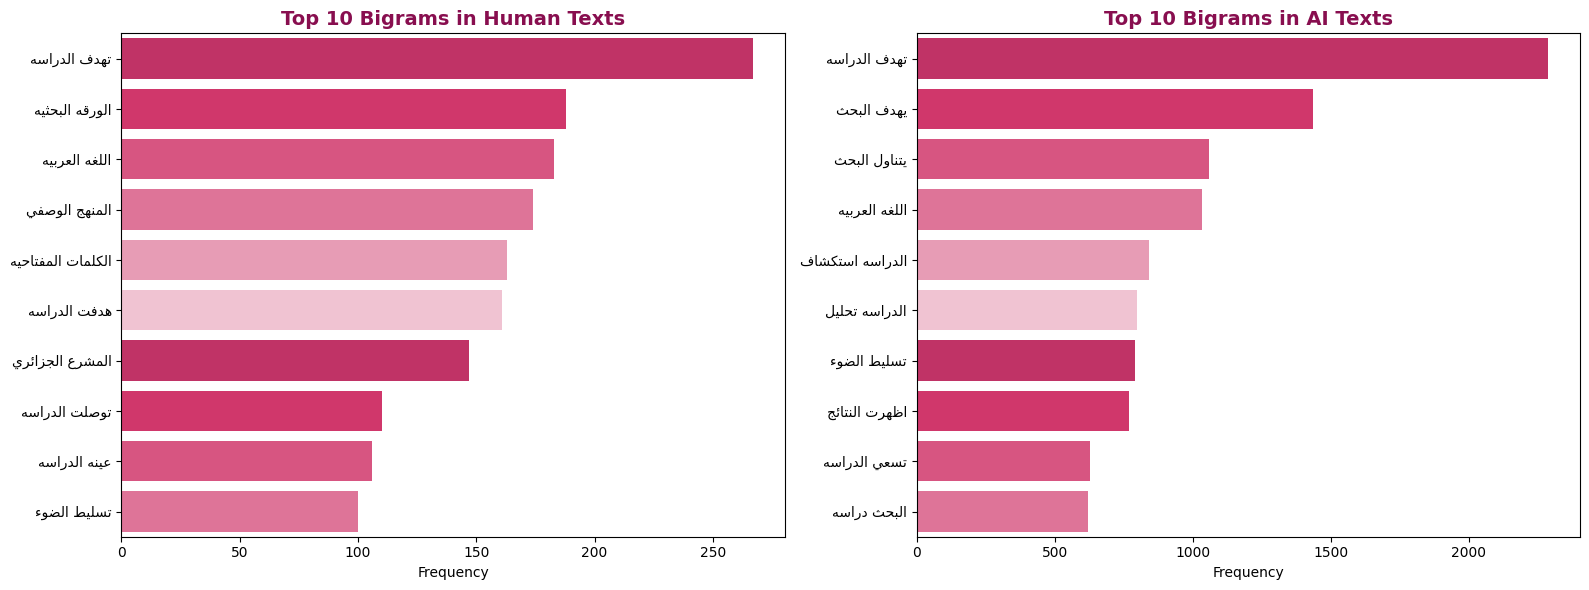

In [14]:
!pip install arabic-reshaper python-bidi
import arabic_reshaper
from bidi.algorithm import get_display

def reshape_arabic(text: str) -> str:
    """Reshapes Arabic text for correct right-to-left rendering in Matplotlib."""
    if not isinstance(text, str):
        return ""
    reshaped = arabic_reshaper.reshape(text)
    return get_display(reshaped)

def plot_top_ngrams(df, text_col='text_no_stopwords', n_gram_range=(2, 2), top_n=10):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    #custom pink palette
    soft_pink_palette = ['#d81b60', '#e91e63', '#ec407a', '#f06292', '#f48fb1', '#f8bbd0']

    for i, label in enumerate(['Human', 'AI']):
        sub_df = df[df['label'] == label]

        #vectorizer
        vec = CountVectorizer(ngram_range=n_gram_range).fit(sub_df[text_col])
        bag_of_words = vec.transform(sub_df[text_col])
        sum_words = bag_of_words.sum(axis=0)

        #top n-grams
        words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
        words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)[:top_n]

        ngrams_df = pd.DataFrame(words_freq, columns=['Ngram', 'Count'])

        #Arabic n-grams for Matplotlib display
        ngrams_df['Ngram_Display'] = ngrams_df['Ngram'].apply(reshape_arabic)

        # Plot with soft pink palette
        sns.barplot(
            x='Count',
            y='Ngram_Display',
            data=ngrams_df,
            ax=axes[i],
            hue='Ngram_Display',
            palette=soft_pink_palette[:top_n], # Apply soft pinks
            legend=False
        )

        axes[i].set_title(f"Top {top_n} Bigrams in {label} Texts", fontsize=14, color='#880e4f', fontweight='bold')
        axes[i].set_xlabel("Frequency")
        axes[i].set_ylabel("")

    plt.tight_layout()
    plt.show()

plot_top_ngrams(stats_df, text_col='text_no_stopwords', n_gram_range=(2, 2), top_n=10)

**Features Engneering**

*   Brunet's W


*   Number of nouns
*   Number of accusatives


*   Gini coefficient of word frequencies
*   Link frequency






Brunet's W

In [37]:
def brunet_w(abstract):
    words = abstract.split()
    N, V  = len(words), len(set(words))
    if N == 0:
        return 0
    return (N ** (V ** -0.172))
  # N is the total number of words
  #V is the number of different words
  # burent formla W = N^(V^−0.172)


Gini coefficient of word frequencies





In [20]:
def gini_word_freq(abstract):
    words = abstract.split()
    word_freq = Counter(words)
    sorted_freq = sorted(word_freq.values())

    V = len(sorted_freq)
    if V == 0:
        return 0
    total = sum(sorted_freq)

    weighted = 0
    for i, f in enumerate(sorted_freq):
        weighted += (i + 1) * f

    return (2 * weighted) / (V * total) - (V + 1) / V



In [21]:
def link_freq(abstract):
    link_pattern = r'(https?://\S+|www\.\S+|doi\.org/\S+)'
    if not isinstance(abstract, str):
        return 0
    n_words = max(len(abstract.split()), 1)
    links = re.findall(link_pattern, abstract, flags=re.IGNORECASE)
    return len(links) / n_words * 100

In [32]:
!pip install camel-tools
!camel_data -i light

The following packages will be installed: 'disambig-mle-calima-msa-r13', 'morphology-db-glf-01', 'morphology-db-msa-s31', 'dialectid-model26', 'disambig-mle-calima-egy-r13', 'morphology-db-lev-01', 'morphology-db-egy-r13'
Extracting package 'disambig-mle-calima-msa-r13': 100% 88.7M/88.7M [00:00<00:00, 327MB/s]
Extracting package 'morphology-db-glf-01': 100% 7.98M/7.98M [00:00<00:00, 517MB/s]
Extracting package 'morphology-db-msa-s31': 100% 44.8M/44.8M [00:00<00:00, 444MB/s]
Extracting package 'dialectid-model26': 100% 275M/275M [00:00<00:00, 381MB/s]
Extracting package 'disambig-mle-calima-egy-r13': 100% 27.2M/27.2M [00:00<00:00, 587MB/s]
Extracting package 'morphology-db-lev-01': 100% 10.6M/10.6M [00:00<00:00, 812MB/s]
Extracting package 'morphology-db-egy-r13': 100% 67.3M/67.3M [00:00<00:00, 487MB/s]


In [33]:
#declaring word type using camel tools (noun/verbs and case : مرفوع، منصوب)
def analyze_text(abstract):
    from camel_tools.tokenizers.word import simple_word_tokenize
    if not isinstance(abstract, str) or not abstract.strip():
        return []
    tokens = simple_word_tokenize(abstract)
    analyses = [d.analyses[0].analysis for d in _get_camel().disambiguate(tokens) if d.analyses]
    return [a for a in analyses if a.get('pos') not in ('punc', 'digit', 'latin')]

In [23]:
def noun_ratio(analyses):
    n = max(len(analyses), 1)
    nouns = sum(a.get('pos') == 'noun' for a in analyses)
    return nouns / n

In [24]:
def accusative_ratio(analyses):
    n = max(len(analyses), 1)
    acc = sum(a.get('cas') == 'a' for a in analyses)
    return acc / n

In [35]:


i = 0
print(brunet_w(df_long['text_normalized'].iloc[i]))
print(gini_word_freq(df_long['text_normalized'].iloc[i]))
print(link_freq(df_long['text'].iloc[i]))
a = analyze_text(df_long['text_cleaned'].iloc[i])
print(noun_ratio(a), accusative_ratio(a))

1.4693308302951458
0.15567439096850855
0.0
0.47368421052631576 0.06140350877192982


In [36]:
df_long['brunet_w']  = df_long['text_normalized'].apply(brunet_w)
df_long['gini']      = df_long['text_normalized'].apply(gini_word_freq)
df_long['link_freq'] = df_long['text'].apply(link_freq)

analyses = df_long['text_cleaned'].apply(analyze_text)   # slow, a few minutes
df_long['noun_ratio'] = analyses.apply(noun_ratio)
df_long['acc_ratio']  = analyses.apply(accusative_ratio)

KeyboardInterrupt: 

In [ ]:
#Build processed dataframe containing all pipeline stages
processed_df = df_long[[
    'task_split',
    'model_source',
    'label',
    'text',               # Raw text
    'text_cleaned',       # Cleaned text
    'text_normalized',    # Normalized text
    'text_no_stopwords',  # Stop-words removed text
    'text_stemmed',       # Light stemmed text
    'text_final'          # Final pure Arabic + numbers text
]].copy()

#Save it to a CSV file
output_filename = 'processed_data.csv'
processed_df.to_csv(output_filename, index=False, encoding='utf-8-sig')
print(f"Successfully saved {len(processed_df):,} rows to '{output_filename}'!")

